# TSLA Machine Learning Trading Model
### Module 3 Project — Predicting TSLA's 20-day price direction to support daily positioning decisions

This notebook follows the **Module 3 Project Assignment** structure. Each numbered section matches a presentation point:

| # | Assignment point | Section in this notebook |
|---|---|---|
| 1 | Problem statement | §1 |
| 2 | Type of ML problem | §2 |
| 3 | Dataset | §3 |
| 4 | EDA findings | §4 |
| 5 | Feature engineering & leakage control | §5 |
| 6 | Models tried (baseline → complex) | §6 |
| 7 | Hyperparameter tuning & findings | §7 |
| 8 | Evaluation metrics & error analysis | §8 |
| 9 | Opportunity sizing | §9 |
| 10 | Deploy / don't-deploy recommendation | §10 |
| 11 | Deployment plan | §11 |
| 12 | GitHub repo & README | §12 (writes `requirements.txt` at the start and generates `README.md` with your results) |

**Run order:** *Kernel → Restart & Run All.* All figures and tables are also saved to `outputs/` for your slides.

## 1. Problem Statement

**Business context.** An investment desk (for example, a small fund or a robo-advisory team) holds Tesla (TSLA) as a core position. Each trading day it must decide how to position TSLA for the coming week: **long, flat, or short**.

**Who is affected?** The portfolio manager who takes the decision, and the clients whose returns and drawdowns depend on it.

**Decision the model supports.** After the market closes on day *t*, the model estimates the probability that TSLA will rise more than +6%, fall more than −6%, or stay in between over the next 5 trading days. A **confidence threshold** turns those probabilities into an action: Buy (long), Sell (short), or Hold (no position).

**How it is handled today (baseline).** The default is passive **buy-and-hold**: always long TSLA, no timing. A machine-learning model is only worth deploying if, **after transaction costs**, it beats buy-and-hold on **risk-adjusted return** (Sharpe ratio) or materially reduces **drawdowns**.

**Success criteria (decided before modelling):**
1. Out-of-sample Sharpe ratio above buy-and-hold, after 0.1% costs per trade.
2. Improvement that is unlikely to be luck (bootstrap confidence interval on excess return above 0).
3. Value created exceeds the cost of building and running the model.

## 2. Type of ML Problem

| Question | Answer | Why |
|---|---|---|
| Supervised or unsupervised? | **Supervised** | Each day has a known outcome (the realised 20-day return), which becomes the label. |
| Classification or regression? | **Classification** | The desk acts on a direction (Buy / Hold / Sell), not an exact return. Predicting exact returns is much noisier. |
| Binary or multi-class? | **Multi-class (3 classes)** | Buy (+1), Hold (0), Sell (−1). Hold matters: it lets the model stay out when it is unsure. |
| Batch or real-time? | **Daily batch** | One prediction per day after the close; no intraday latency requirement. |
| Time series? | **Yes** | Rows are ordered in time, so we **never shuffle**: chronological splits and `TimeSeriesSplit` cross-validation only. |

### Setup 1: libraries and configuration

In [36]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             roc_auc_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 10, "axes.titleweight": "bold"})

COLORS = {"strategy": "#2563eb", "buyhold": "#6b7280", -1: "#dc2626", 0: "#9ca3af", 1: "#16a34a"}
CLASS_NAMES = {-1: "Sell (-1)", 0: "Hold (0)", 1: "Buy (1)"}

In [37]:
# ==========================================
# ADJUSTABLE PROJECT PARAMETERS
# ==========================================
TICKER          = "TSLA"
START_DATE      = "2012-01-01"
END_DATE        = "2026-10-01"   # Ends test period at 2026-10-01
VAL_START       = "2021-01-01"   # Validation covers 2021 to 2022
TEST_START      = "2023-01-01"   # Test covers 2023 through 2026-10-01

# Target definition
FUTURE_PERIOD   = 20            # look-ahead horizon in trading days
BUY_THRESHOLD   = 0.06          # future return > +6%  -> Buy (1)
SELL_THRESHOLD  = -0.06         # future return < -6%  -> Sell (-1)

# Backtest assumptions
INITIAL_CAPITAL = 100_000.0
TRANSACTION_FEE = 0.001          # 0.1% per unit of position change (fees + slippage)
RISK_FREE_RATE  = 0.02           # annual, for Sharpe / Sortino
EXECUTION_LAG   = 2              # signal after close on day t, filled at close of t+1 (see §6)
LONG_ONLY       = False          # True = Sell signals mean "go flat" instead of "go short"
DEFAULT_CONFIDENCE = 0.45        # starting confidence threshold (tuned on validation in §7)
MIN_TRADES      = 6              # threshold search ignores settings with fewer position changes

# Modelling
RANDOM_STATE    = 42
N_CV_SPLITS     = 5
SELECTION_METRIC = "Sharpe"      # how the final model is chosen on validation: "Sharpe" or "Macro F1"

# Outputs (used by README / slides)
OUTPUT_DIR, FIG_DIR, DATA_DIR = "outputs", "outputs/figures", "data"
for d in (OUTPUT_DIR, FIG_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)

def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

np.random.seed(RANDOM_STATE)
print(f"{TICKER}: horizon {FUTURE_PERIOD}d | Buy > {BUY_THRESHOLD:+.1%} | Sell < {SELL_THRESHOLD:+.1%} | "
      f"fee {TRANSACTION_FEE:.1%} | long-only={LONG_ONLY}")

TSLA: horizon 20d | Buy > +6.0% | Sell < -6.0% | fee 0.1% | long-only=False


## 3. Dataset

**Source.** Daily OHLCV (open, high, low, close, volume) bars for TSLA from Yahoo Finance via the `yfinance` library, **split- and dividend-adjusted** (`auto_adjust=True`). Adjustment matters: TSLA had a 5:1 split in 2020 and a 3:1 split in 2022, which would otherwise look like 75–86% one-day crashes.

**Reproducibility.** The first successful download is cached to `data/tsla_ohlcv.csv`; later runs read the cache, so results do not change when Yahoo revises data.

**Offline fallback.** If Yahoo cannot be reached, the notebook generates a **synthetic** random-walk series so the code still runs. Synthetic data has **no real patterns**, so its results must not be presented. The notebook prints a clear warning whenever this happens.

In [38]:
CACHE_FILE = f"{DATA_DIR}/{TICKER.lower()}_ohlcv.csv"

def download_yahoo():
    import yfinance as yf
    df = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
    if df is None or df.empty:                    # yfinance often returns an EMPTY frame instead of raising
        raise ValueError("yfinance returned no rows (network blocked or ticker unavailable)")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    return df

def make_synthetic():
    rng = np.random.default_rng(RANDOM_STATE)
    dates = pd.bdate_range(START_DATE, END_DATE, inclusive="left")
    n = len(dates)
    rets = rng.normal(0.0008, 0.018, n)
    close = 15.0 * np.exp(np.cumsum(rets))
    high = close * (1 + np.abs(rng.normal(0, 0.008, n)))
    low = close * (1 - np.abs(rng.normal(0, 0.008, n)))
    open_ = low + (high - low) * rng.uniform(0.1, 0.9, n)
    vol = rng.integers(40_000_000, 120_000_000, n)
    return pd.DataFrame({"Open": open_, "High": high, "Low": low, "Close": close, "Volume": vol},
                        index=pd.DatetimeIndex(dates, name="Date"))

def load_data():
    if os.path.exists(CACHE_FILE):
        return pd.read_csv(CACHE_FILE, index_col="Date", parse_dates=True), "Yahoo Finance (cached)"
    try:
        df = download_yahoo()
        df.to_csv(CACHE_FILE)
        return df, "Yahoo Finance (downloaded)"
    except Exception as e:
        print(f"WARNING: could not download real data -> using SYNTHETIC data. Reason: {e}")
        return make_synthetic(), "SYNTHETIC (offline fallback)"

df_raw, DATA_SOURCE = load_data()
IS_SYNTHETIC = DATA_SOURCE.startswith("SYNTHETIC")

print(f"Source : {DATA_SOURCE}")
print(f"Rows   : {len(df_raw):,} trading days   Columns: {list(df_raw.columns)}")
print(f"Period : {df_raw.index.min():%Y-%m-%d} to {df_raw.index.max():%Y-%m-%d}")
print(f"Missing values per column:\n{df_raw.isna().sum().to_string()}")
if IS_SYNTHETIC:
    print("\n" + "!" * 80 + "\n  SYNTHETIC DATA: results below are for testing the code only. Re-run with internet access.\n" + "!" * 80)
df_raw.describe().round(2)

Source : Yahoo Finance (cached)
Rows   : 3,707 trading days   Columns: ['Open', 'High', 'Low', 'Close', 'Volume']
Period : 2012-01-03 to 2026-09-30
Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0


,Open,High,Low,Close,Volume
count,3707.00,3707.00,3707.00,3707.00,3.707000e+03
mean,123.85,126.48,121.07,123.82,1.023018e+08
std,138.77,141.62,135.70,138.69,7.385095e+07
min,1.77,1.79,1.51,1.52,5.473500e+06
25%,14.77,15.00,14.53,14.72,5.845350e+07
50%,22.89,23.24,22.46,22.89,8.612400e+07
75%,236.00,240.91,232.27,236.92,1.234976e+08
max,489.88,498.83,485.33,489.88,9.140820e+08


### 3.1 Target variable

For each day *t*, the future 20-day return is

$$R_{t \to t+N} = \frac{\text{Close}_{t+N}}{\text{Close}_t} - 1, \qquad N = 20$$

| Label | Rule | Meaning |
|---|---|---|
| **Buy (+1)** | $R > +6\%$ | worth being long |
| **Sell (−1)** | $R < -6\%$ | worth being short / out |
| **Hold (0)** | otherwise | move too small to cover costs and risk |

The ±6% band is set so that a correct signal clears the round-trip transaction cost with room to spare. The last *N* rows have no future price yet, so they are dropped.

In [39]:
def create_target(df, horizon=FUTURE_PERIOD, buy_thresh=BUY_THRESHOLD, sell_thresh=SELL_THRESHOLD):
    data = df.copy()
    data["Future_Return"] = data["Close"].shift(-horizon) / data["Close"] - 1.0   # uses the FUTURE: label only
    data = data.dropna(subset=["Future_Return"])
    data["Target"] = np.select([data["Future_Return"] > buy_thresh,
                                data["Future_Return"] < sell_thresh], [1, -1], default=0)
    return data

df_target = create_target(df_raw)
dist = df_target["Target"].value_counts(normalize=True).sort_index().rename(CLASS_NAMES)
print("Overall class distribution:\n" + dist.map("{:.1%}".format).to_string())

Overall class distribution:
Target
Sell (-1)    28.6%
Hold (0)     32.0%
Buy (1)      39.4%


## 4. Exploratory Data Analysis

Four key findings, each linked to a modelling decision. (With real data, check the printed numbers match the descriptions before presenting them.)

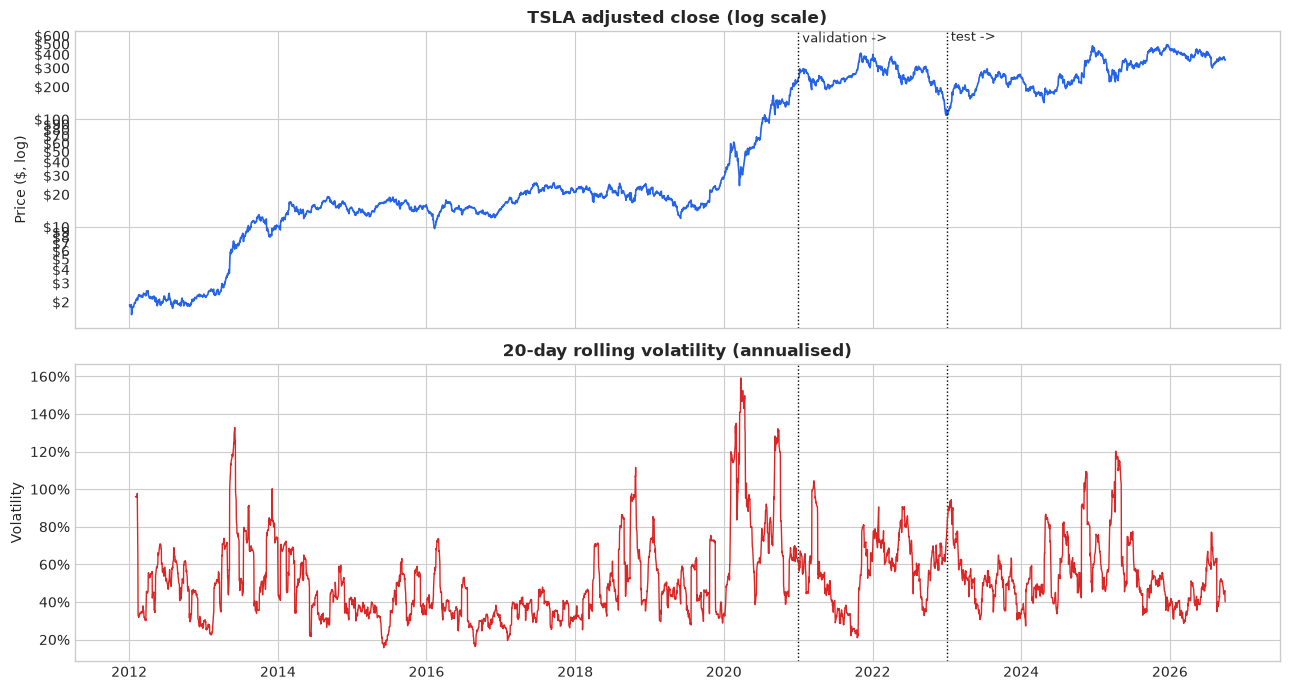

Price grew 189.5x over the period.
Rolling volatility ranged from 16% to 159% (median 48%).


In [40]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(df_raw.index, df_raw["Close"], color=COLORS["strategy"], lw=1.2)
axes[0].set_yscale("log")
axes[0].set_title(f"{TICKER} adjusted close (log scale)")
axes[0].set_ylabel("Price ($, log)")
for d, lbl in [(VAL_START, "validation ->"), (TEST_START, "test ->")]:
    for ax in axes:
        ax.axvline(pd.Timestamp(d), color="black", ls=":", lw=1)
    axes[0].text(pd.Timestamp(d), axes[0].get_ylim()[1], " " + lbl, va="top", fontsize=9)

daily_ret = df_raw["Close"].pct_change()
roll_vol = daily_ret.rolling(20).std() * np.sqrt(252)
axes[1].plot(roll_vol.index, roll_vol, color=COLORS[-1], lw=1)
axes[1].set_title("20-day rolling volatility (annualised)")
axes[1].set_ylabel("Volatility")
from matplotlib.ticker import FuncFormatter, PercentFormatter
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[0].yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout(); save_fig("eda_1_price_and_volatility"); plt.show()

print(f"Price grew {df_raw['Close'].iloc[-1] / df_raw['Close'].iloc[0]:.1f}x over the period.")
print(f"Rolling volatility ranged from {roll_vol.min():.0%} to {roll_vol.max():.0%} (median {roll_vol.median():.0%}).")

**Finding 1: Prices are non-stationary; volatility comes in regimes.**
The price level rises many-fold, so a raw price (or anything in dollars) means something different in 2013 than in 2024. Volatility is not constant: calm periods alternate with turbulent ones (for example, the 2020 crash and 2022 sell-off in real data).

➡ **Modelling choice:** use only **scale-free features** (returns, ratios to moving averages, and MACD *divided by price*), and add **volatility features**. Error analysis in §8 is split by **volatility regime**.

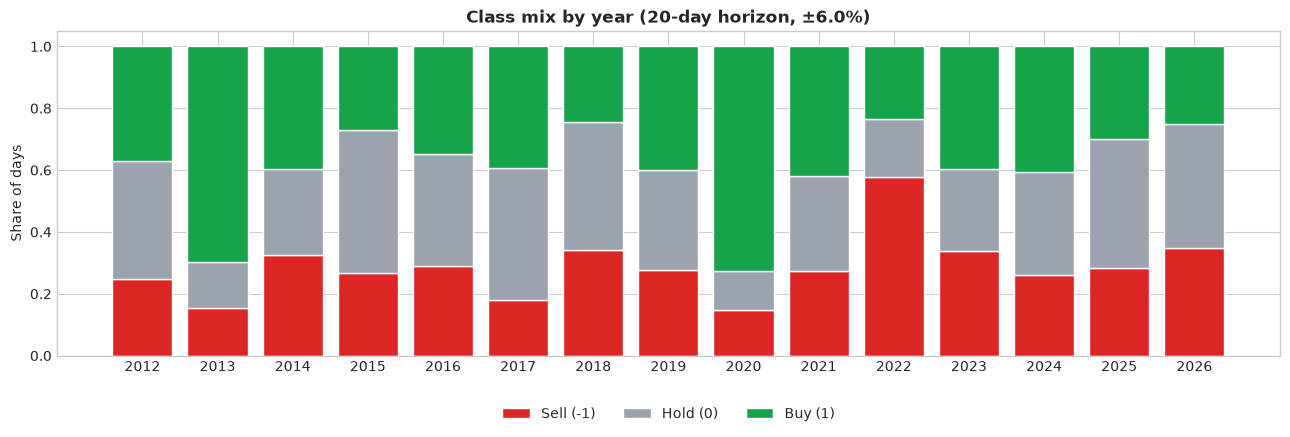

Target Sell (-1) Hold (0) Buy (1)
Date                             
2012         25%      38%     37%
2013         15%      15%     70%
2014         33%      28%     40%
2015         27%      46%     27%
2016         29%      36%     35%
2017         18%      43%     39%
2018         34%      41%     24%
2019         28%      32%     40%
2020         15%      13%     73%
2021         27%      31%     42%
2022         58%      19%     24%
2023         34%      26%     40%
2024         26%      33%     40%
2025         28%      42%     30%
2026         35%      40%     25%


In [41]:
by_year = (df_target.groupby(df_target.index.year)["Target"]
           .value_counts(normalize=True).unstack().reindex(columns=[-1, 0, 1]).fillna(0))
fig, ax = plt.subplots(figsize=(13, 4.5))
bottom = np.zeros(len(by_year))
for c in [-1, 0, 1]:
    ax.bar(by_year.index.astype(str), by_year[c], bottom=bottom, color=COLORS[c], label=CLASS_NAMES[c], edgecolor="white")
    bottom += by_year[c].values
ax.set_title(f"Class mix by year ({FUTURE_PERIOD}-day horizon, ±{BUY_THRESHOLD:.1%})")
ax.set_ylabel("Share of days"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); save_fig("eda_2_class_mix_by_year"); plt.show()
print(by_year.rename(columns=CLASS_NAMES).map("{:.0%}".format).to_string())

**Finding 2: The three classes are roughly balanced overall, but the mix shifts from year to year.**
No class is tiny, yet bull years tilt towards Buy and bear years (such as 2022) towards Sell. A model trained on mostly bullish years may over-predict Buy.

➡ **Modelling choice:** `class_weight="balanced"`; judge models on **macro F1** (every class counts equally) rather than accuracy; compare against a **majority-class baseline**; check performance **per period** in error analysis.

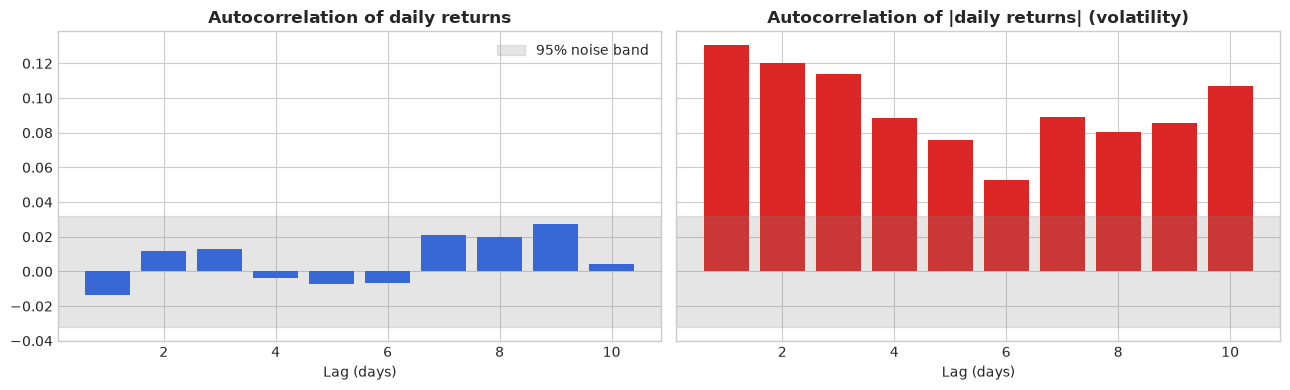

Mean |autocorr| of returns, lags 1-10: 0.013  (noise band ±0.032)
Mean autocorr of |returns|, lags 1-10: 0.094


In [42]:
lags = range(1, 11)
acf_ret = [daily_ret.autocorr(l) for l in lags]
acf_abs = [daily_ret.abs().autocorr(l) for l in lags]
conf = 1.96 / np.sqrt(daily_ret.notna().sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
axes[0].bar(list(lags), acf_ret, color=COLORS["strategy"])
axes[0].set_title("Autocorrelation of daily returns")
axes[1].bar(list(lags), acf_abs, color=COLORS[-1])
axes[1].set_title("Autocorrelation of |daily returns| (volatility)")
for ax in axes:
    ax.axhspan(-conf, conf, color="grey", alpha=0.2, label="95% noise band")
    ax.set_xlabel("Lag (days)")
axes[0].legend()
plt.tight_layout(); save_fig("eda_3_autocorrelation"); plt.show()
print(f"Mean |autocorr| of returns, lags 1-10: {np.mean(np.abs(acf_ret)):.3f}  (noise band ±{conf:.3f})")
print(f"Mean autocorr of |returns|, lags 1-10: {np.mean(acf_abs):.3f}")

**Finding 3: Direction is close to unpredictable from past returns alone; volatility is much more predictable.**
Return autocorrelations sit mostly inside the noise band, while absolute returns are positively autocorrelated (volatility clustering) in real market data.

➡ **Modelling choice:** expect only a **small edge**. Use **regularised, shallow models** to avoid fitting noise; insist on beating simple **baselines**; use a **Hold** class and a **confidence threshold** so the model only trades when it is relatively sure.

## 5. Feature Engineering and Leakage Control

All features use **only information available at the close of day *t***: rolling windows and exponential averages look backwards, and nothing uses `shift(-k)`. Only the **target** looks forward.

| Group | Features | Reasoning |
|---|---|---|
| Momentum | `Return_1D/5D/10D/21D/63D` | Recent trend over a day, week, fortnight, month, quarter |
| Trend position | `Ratio_SMA10/50/200`, `Dist_52W_High` | Where price sits relative to its averages / yearly high |
| Oscillators | `RSI_14`, `BB_PctB` | Overbought / oversold signals |
| MACD (normalised) | `MACD_Pct`, `MACD_Signal_Pct`, `MACD_Hist_Pct` | **Changed from the original**: raw MACD is in dollars and grows with price (Finding 1), so it is divided by price |
| Volatility | `Vol_20D`, `Vol_Ratio_20_60`, `HL_Range_14` | Volatility level and whether it is rising; intraday range |
| Volume | `Volume_Ratio` | Unusual trading activity |

**Cleaning.** Rows in the warm-up period (first ~252 days, needed for the 52-week high and 200-day average) are dropped; there are no other missing values. **Scaling** is applied only to Logistic Regression, inside a `Pipeline`, so the scaler is fitted on training folds only. Tree models do not need scaling. There are no categorical columns, so no encoding is needed.

In [43]:
def build_features(df):
    d = df.copy()
    c = d["Close"]
    # Momentum
    for n in (1, 5, 10, 21, 63):
        d[f"Return_{n}D"] = c.pct_change(n)
    # Trend position
    for n in (10, 50, 200):
        d[f"Ratio_SMA{n}"] = c / c.rolling(n).mean()
    d["Dist_52W_High"] = c / c.rolling(252).max() - 1
    # RSI (14)
    delta = c.diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    d["RSI_14"] = 100 - 100 / (1 + gain / (loss + 1e-8))
    # MACD, normalised by price so it is comparable across years
    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    signal = macd.ewm(span=9, adjust=False).mean()
    d["MACD_Pct"], d["MACD_Signal_Pct"], d["MACD_Hist_Pct"] = macd / c, signal / c, (macd - signal) / c
    # Bollinger %B
    mid, sd = c.rolling(20).mean(), c.rolling(20).std()
    d["BB_PctB"] = (c - (mid - 2 * sd)) / (4 * sd + 1e-8)
    # Volatility
    r = c.pct_change()
    d["Vol_20D"] = r.rolling(20).std()
    d["Vol_Ratio_20_60"] = d["Vol_20D"] / (r.rolling(60).std() + 1e-8)
    d["HL_Range_14"] = ((d["High"] - d["Low"]) / c).rolling(14).mean()
    # Volume
    d["Volume_Ratio"] = d["Volume"] / (d["Volume"].rolling(20).mean() + 1e-8)
    return d

FEATURE_COLS = ["Return_1D", "Return_5D", "Return_10D", "Return_21D", "Return_63D",
                "Ratio_SMA10", "Ratio_SMA50", "Ratio_SMA200", "Dist_52W_High",
                "RSI_14", "MACD_Pct", "MACD_Signal_Pct", "MACD_Hist_Pct", "BB_PctB",
                "Vol_20D", "Vol_Ratio_20_60", "HL_Range_14", "Volume_Ratio"]

df_model = create_target(build_features(df_raw))
df_model = df_model.dropna(subset=FEATURE_COLS)
print(f"Modelling table: {len(df_model):,} rows x {len(FEATURE_COLS)} features "
      f"({df_model.index.min():%Y-%m-%d} to {df_model.index.max():%Y-%m-%d})")

# Leakage self-check: features computed on data truncated at day t must equal features computed on the full history
t = df_raw.index[len(df_raw) // 2]
full_row = build_features(df_raw).loc[t, FEATURE_COLS]
trunc_row = build_features(df_raw.loc[:t]).loc[t, FEATURE_COLS]
assert np.allclose(full_row.values, trunc_row.values, equal_nan=True), "Look-ahead leakage detected!"
print(f"Leakage check passed: features on {t:%Y-%m-%d} are identical with or without future data.")

Modelling table: 3,436 rows x 18 features (2013-01-03 to 2026-09-01)
Leakage check passed: features on 2019-05-16 are identical with or without future data.


### 5.1 Chronological split with purging

Train 2012–2020 · Validation 2021–2022 · Test 2023–2026 (sealed).

**Why purge?** A label on 28 Dec 2020 depends on prices up to early January 2021, which fall inside the validation period. Keeping it in training would leak validation information. We therefore **drop the last `FUTURE_PERIOD` rows before each boundary**. Cross-validation uses `TimeSeriesSplit(gap=FUTURE_PERIOD)` for the same reason.

In [44]:
def purged_index(df, end, start=None, purge=FUTURE_PERIOD):
    idx = df.index[df.index < pd.Timestamp(end)]
    if start is not None:
        idx = idx[idx >= pd.Timestamp(start)]
    return idx[:-purge] if purge > 0 else idx

train_idx = purged_index(df_model, VAL_START)
val_idx   = purged_index(df_model, TEST_START, start=VAL_START)
test_idx  = df_model.index[df_model.index >= pd.Timestamp(TEST_START)]
trval_idx = purged_index(df_model, TEST_START)          # used only for the final refit in §8

X_train, y_train = df_model.loc[train_idx, FEATURE_COLS], df_model.loc[train_idx, "Target"]
X_val,   y_val   = df_model.loc[val_idx,   FEATURE_COLS], df_model.loc[val_idx,   "Target"]
X_test,  y_test  = df_model.loc[test_idx,  FEATURE_COLS], df_model.loc[test_idx,  "Target"]

split_summary = pd.DataFrame({
    "Rows": [len(train_idx), len(val_idx), len(test_idx)],
    "From": [i.min().date() for i in (train_idx, val_idx, test_idx)],
    "To":   [i.max().date() for i in (train_idx, val_idx, test_idx)],
    **{CLASS_NAMES[c]: [f"{(y == c).mean():.0%}" for y in (y_train, y_val, y_test)] for c in (-1, 0, 1)},
}, index=["Train", "Validation", "Test (sealed)"])
split_summary

,Rows,From,To,Sell (-1),Hold (0),Buy (1)
Train,1994,2013-01-03,2020-12-02,25%,32%,43%
Validation,483,2021-01-04,2022-12-01,42%,25%,33%
Test (sealed),919,2023-01-03,2026-09-01,30%,35%,35%


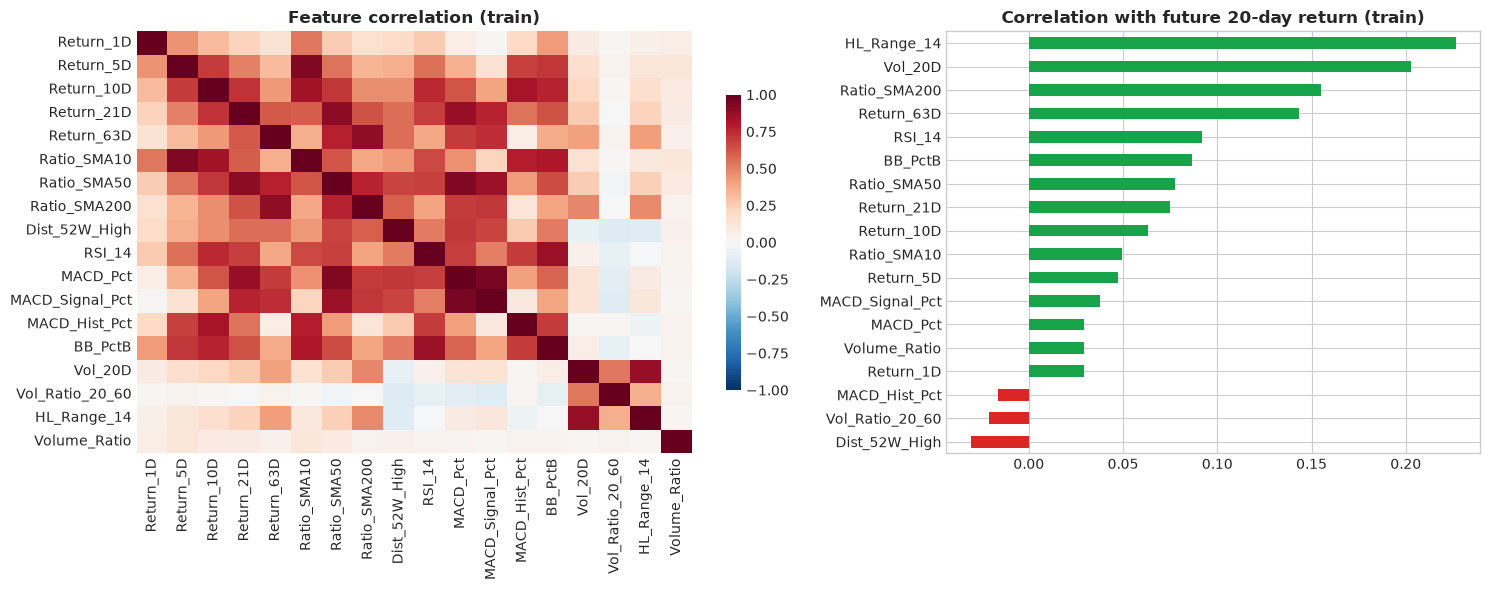

Strongest single-feature correlation with future return: 0.227
Highly correlated feature pairs (|r| > 0.85): 9
MACD_Pct     MACD_Signal_Pct    0.95
Return_5D    Ratio_SMA10        0.93
Ratio_SMA50  MACD_Pct           0.93
Return_21D   Ratio_SMA50        0.90
Return_63D   Ratio_SMA200       0.89
Return_21D   MACD_Pct           0.87
Vol_20D      HL_Range_14        0.87
Ratio_SMA50  MACD_Signal_Pct    0.86
RSI_14       BB_PctB            0.86


In [45]:
# Feature diagnostics on TRAINING data only (looking at test data here would be a subtle form of leakage)
train_block = df_model.loc[train_idx, FEATURE_COLS + ["Future_Return"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(train_block[FEATURE_COLS].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[0].set_title("Feature correlation (train)")
corr_target = train_block.corr()["Future_Return"].drop("Future_Return").sort_values()
corr_target.plot(kind="barh", ax=axes[1], color=[COLORS[1] if v > 0 else COLORS[-1] for v in corr_target])
axes[1].set_title("Correlation with future 20-day return (train)")
plt.tight_layout(); save_fig("eda_4_feature_correlations"); plt.show()

high_pairs = (train_block[FEATURE_COLS].corr().abs().where(lambda m: np.triu(np.ones(m.shape, bool), 1))
              .stack().loc[lambda s: s > 0.85].sort_values(ascending=False))
print(f"Strongest single-feature correlation with future return: {corr_target.abs().max():.3f}")
print(f"Highly correlated feature pairs (|r| > 0.85): {len(high_pairs)}")
print(high_pairs.round(2).to_string() if len(high_pairs) else "  none")

**Finding 4: Each feature alone has a very weak link with future returns (|r| typically well below 0.1), and several features overlap heavily** (for example the MACD variants and the short-term moving-average ratios).

➡ **Modelling choice:** no single rule will work, so we try models that **combine weak signals non-linearly** (Random Forest, Gradient Boosting). Overlapping features are harmless for trees; for Logistic Regression, **L2 regularisation** (tuned `C`) keeps coefficients stable.

## 6. Models Tried: from baselines to more complex models

**Evaluation helpers.**
- **Signals:** a non-Hold signal is issued only if its class probability is at least the confidence threshold *and* higher than the opposite class. Otherwise the model holds no position.
- **Backtest:** the signal is computed after the close on day *t* and **filled at the close of day *t*+1**, so the first return earned is from close *t*+1 to close *t*+2 (`EXECUTION_LAG = 2`). *The original notebook used `shift(1)`, which effectively traded at the same close the signal was computed from; that is slightly optimistic.* Each unit of position change pays 0.1%, so flipping from short to long costs 0.2%. Buy-and-hold pays one entry fee.
- **Metrics:** classification metrics (macro F1, balanced accuracy, per-class precision, ROC AUC) plus business metrics (Sharpe, CAGR, max drawdown, number of trades).

In [46]:
def signals_from_proba(proba, classes, threshold):
    classes = list(classes)
    p_buy, p_sell = proba[:, classes.index(1)], proba[:, classes.index(-1)]
    sig = np.zeros(len(proba), dtype=int)
    sig[(p_buy >= threshold) & (p_buy > p_sell)] = 1
    sig[(p_sell >= threshold) & (p_sell > p_buy)] = -1
    return sig

def run_backtest(close, signals, lag=EXECUTION_LAG, fee=TRANSACTION_FEE, long_only=LONG_ONLY, capital=INITIAL_CAPITAL):
    bt = pd.DataFrame({"Close": close.values, "Signal": np.asarray(signals)}, index=close.index)
    if long_only:
        bt["Signal"] = bt["Signal"].clip(lower=0)
    bt["Position"] = bt["Signal"].shift(lag).fillna(0)
    bt["Stock_Return"] = bt["Close"].pct_change().fillna(0)
    bt["Turnover"] = bt["Position"].diff().abs().fillna(bt["Position"].abs())
    bt["Strategy_Return"] = bt["Position"] * bt["Stock_Return"] - bt["Turnover"] * fee
    bt["BuyHold_Return"] = bt["Stock_Return"]
    bt.iloc[0, bt.columns.get_loc("BuyHold_Return")] -= fee
    bt["Strategy_Equity"] = capital * (1 + bt["Strategy_Return"]).cumprod()
    bt["BuyHold_Equity"] = capital * (1 + bt["BuyHold_Return"]).cumprod()
    return bt

def financial_metrics(r, capital=INITIAL_CAPITAL, rf=RISK_FREE_RATE):
    r = pd.Series(r).fillna(0)
    equity = capital * (1 + r).cumprod()
    years = len(r) / 252
    sd = r.std()
    excess = r - rf / 252
    downside = np.sqrt((np.minimum(r, 0) ** 2).mean())
    return {
        "Total Return": equity.iloc[-1] / capital - 1,
        "CAGR": (equity.iloc[-1] / capital) ** (1 / years) - 1,
        "Volatility": sd * np.sqrt(252),
        "Sharpe": excess.mean() / sd * np.sqrt(252) if sd > 1e-12 else np.nan,
        "Sortino": excess.mean() / downside * np.sqrt(252) if downside > 1e-12 else np.nan,
        "Max Drawdown": (equity / equity.cummax() - 1).min(),
    }

def evaluate(model, X, y, idx, threshold, name=""):
    proba = model.predict_proba(X)
    sig = signals_from_proba(proba, model.classes_, threshold)
    bt = run_backtest(df_model.loc[idx, "Close"], sig)
    fm = financial_metrics(bt["Strategy_Return"])
    try:
        auc = roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=list(model.classes_))
    except ValueError:
        auc = np.nan
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y, sig),
        "Balanced Acc": balanced_accuracy_score(y, sig),
        "Macro F1": f1_score(y, sig, average="macro", labels=[-1, 0, 1], zero_division=0),
        "Buy Precision": precision_score(y, sig, labels=[1], average="macro", zero_division=0),
        "Sell Precision": precision_score(y, sig, labels=[-1], average="macro", zero_division=0),
        "ROC AUC (OvR)": auc,
        "Sharpe": fm["Sharpe"], "CAGR": fm["CAGR"], "Max Drawdown": fm["Max Drawdown"],
        "Trades": int((bt["Turnover"] > 0).sum()),
        "% Days in Market": (bt["Position"] != 0).mean(),
    }
    return row, sig, proba, bt

def buyhold_row(idx, name="Buy & Hold (current process)"):
    bt = run_backtest(df_model.loc[idx, "Close"], np.ones(len(idx), dtype=int))
    fm = financial_metrics(bt["BuyHold_Return"])
    return {"Model": name, "Sharpe": fm["Sharpe"], "CAGR": fm["CAGR"], "Max Drawdown": fm["Max Drawdown"],
            "Trades": 1, "% Days in Market": 1.0}

PCT_COLS = ["Accuracy", "Balanced Acc", "Macro F1", "Buy Precision", "Sell Precision", "CAGR",
            "Max Drawdown", "% Days in Market", "Train Macro F1"]
def show_table(rows):
    t = pd.DataFrame(rows).set_index("Model")
    fmt = {c: "{:.1%}" for c in PCT_COLS if c in t}
    fmt.update({c: "{:.2f}" for c in ("ROC AUC (OvR)", "Sharpe") if c in t})
    fmt.update({c: "{:.0f}" for c in ("Trades",) if c in t})
    return t, t.style.format(fmt, na_rep="–")

### 6.1 Candidate models (default settings), scored on validation (2021–2022)

| Model | Role |
|---|---|
| Buy & Hold | Current process: the bar every model must beat |
| Majority-class `DummyClassifier` | "No-skill" ML baseline: always predicts the most common class |
| Logistic Regression (scaled, L2) | Simple, interpretable linear model |
| Random Forest (original v1 settings) | Bagging ensemble from the first version of this notebook |
| Histogram Gradient Boosting | Boosting ensemble: usually strongest on tabular data |

`Train Macro F1` is shown next to the validation scores so that a large gap reveals **overfitting** (high variance).

In [47]:
candidate_models = {
    "Majority class (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))]),
    "Random Forest (v1)": RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=25,
                                                 class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                        class_weight="balanced", random_state=RANDOM_STATE),
}

rows = [buyhold_row(val_idx)]
fitted_default = {}
for name, model in candidate_models.items():
    m = clone(model).fit(X_train, y_train)
    fitted_default[name] = m
    row, *_ = evaluate(m, X_val, y_val, val_idx, DEFAULT_CONFIDENCE, name)
    train_sig = signals_from_proba(m.predict_proba(X_train), m.classes_, DEFAULT_CONFIDENCE)
    row["Train Macro F1"] = f1_score(y_train, train_sig, average="macro", labels=[-1, 0, 1], zero_division=0)
    rows.append(row)

default_table, styled = show_table(rows)
default_table.to_csv(f"{OUTPUT_DIR}/model_comparison_default.csv")
print(f"Validation period, confidence threshold = {DEFAULT_CONFIDENCE}")
styled

Validation period, confidence threshold = 0.45


,Sharpe,CAGR,Max Drawdown,Trades,% Days in Market,Accuracy,Balanced Acc,Macro F1,Buy Precision,Sell Precision,ROC AUC (OvR),Train Macro F1
Model,,,,,,,,,,,,
Buy & Hold (current process),0.07,-11.0%,-59.1%,1,100.0%,–,–,–,–,–,–,–
Majority class (Dummy),0.07,-11.4%,-59.1%,1,99.6%,32.9%,33.3%,16.5%,32.9%,0.0%,0.50,20.0%
Logistic Regression,0.52,16.5%,-35.9%,69,44.3%,28.8%,32.4%,26.1%,36.4%,50.0%,0.47,40.6%
Random Forest (v1),0.33,7.4%,-42.5%,35,30.6%,27.3%,33.2%,22.9%,26.7%,100.0%,0.44,38.9%
Gradient Boosting,-0.47,-31.4%,-67.4%,107,74.5%,30.6%,31.6%,28.6%,29.2%,49.2%,0.46,87.2%


**How to read this table:** a model only earns its complexity if it beats **both** baselines: higher macro F1 than the Dummy, and higher Sharpe (or smaller drawdown) than Buy & Hold. A big gap between `Train Macro F1` and `Macro F1` means the model memorised noise.

## 7. Hyperparameter Tuning

- **Method:** `GridSearchCV` with **`TimeSeriesSplit(n_splits=20, gap=20)`** on the **training set only**: each fold trains on earlier years and validates on the next block, with a 20-day gap so overlapping labels cannot leak.
- **Scoring:** macro F1 (treats Buy, Hold and Sell equally, matching Finding 2).
- **The test set stays sealed.** Model choice and confidence threshold are decided on the 2021–2022 validation set.

In [48]:
tscv = TimeSeriesSplit(n_splits=N_CV_SPLITS, gap=FUTURE_PERIOD)

search_spaces = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
        {"clf__C": [0.001, 0.01, 0.1, 1.0, 10.0]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=1),
        {"max_depth": [3, 4, 6, 8], "min_samples_leaf": [10, 25, 50], "max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 5], "max_iter": [100, 300], "l2_regularization": [0.0, 1.0]}),
}

searches = {}
for name, (est, grid) in search_spaces.items():
    gs = GridSearchCV(est, grid, cv=tscv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    best = gs.cv_results_
    i = gs.best_index_
    print(f"{name:20s} best CV macro F1 = {gs.best_score_:.3f} (train {best['mean_train_score'][i]:.3f}, "
          f"fold std {best['std_test_score'][i]:.3f})  params = {gs.best_params_}")

Logistic Regression  best CV macro F1 = 0.311 (train 0.506, fold std 0.057)  params = {'clf__C': 0.1}
Random Forest        best CV macro F1 = 0.349 (train 0.608, fold std 0.099)  params = {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 10}
Gradient Boosting    best CV macro F1 = 0.332 (train 1.000, fold std 0.059)  params = {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 300}


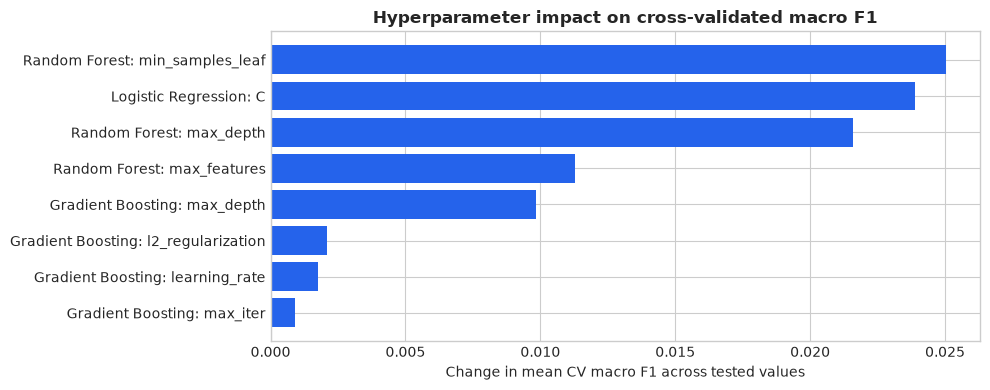

,Model,Hyperparameter,Effect (max - min CV F1),Best value,Mean CV F1 by value
0,Random Forest,min_samples_leaf,0.025043,10,"{'10': 0.322, '25': 0.319, '50': 0.297}"
1,Logistic Regression,C,0.023893,0.1,"{'0.001': 0.293, '0.01': 0.303, '0.1': 0.311, ..."
2,Random Forest,max_depth,0.021606,3,"{'3': 0.326, '4': 0.317, '6': 0.305, '8': 0.304}"
3,Random Forest,max_features,0.011287,sqrt,"{'0.5': 0.307, 'sqrt': 0.318}"
4,Gradient Boosting,max_depth,0.009830,5,"{'2': 0.315, '3': 0.318, '5': 0.325}"
5,Gradient Boosting,l2_regularization,0.002093,1.0,"{'0.0': 0.318, '1.0': 0.32}"
6,Gradient Boosting,learning_rate,0.001750,0.1,"{'0.03': 0.319, '0.1': 0.32}"
7,Gradient Boosting,max_iter,0.000909,300,"{'100': 0.319, '300': 0.32}"


In [49]:
# Which hyperparameter mattered most? Effect = spread of mean CV score across that parameter's values
effects = []
for name, gs in searches.items():
    res = pd.DataFrame(gs.cv_results_)
    for p in gs.param_grid:
        by_val = res.groupby(res[f"param_{p}"].astype(str))["mean_test_score"].mean()
        effects.append({"Model": name, "Hyperparameter": p.replace("clf__", ""),
                        "Effect (max - min CV F1)": by_val.max() - by_val.min(),
                        "Best value": by_val.idxmax(), "Mean CV F1 by value": by_val.round(3).to_dict()})
effects = pd.DataFrame(effects).sort_values("Effect (max - min CV F1)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
labels = effects["Model"] + ": " + effects["Hyperparameter"]
ax.barh(labels[::-1], effects["Effect (max - min CV F1)"][::-1], color=COLORS["strategy"])
ax.set_title("Hyperparameter impact on cross-validated macro F1")
ax.set_xlabel("Change in mean CV macro F1 across tested values")
plt.tight_layout(); save_fig("tuning_hyperparameter_effects"); plt.show()
effects.reset_index(drop=True)

**Interpreting the tuning results.** In noisy financial data, the parameters that control **model complexity** (tree depth, minimum leaf size, regularisation strength `C`, learning rate) usually matter most. Shallower trees, larger leaves and stronger regularisation reduce **variance**: the model stops memorising day-to-day noise. Compare `best CV` with `train` scores above: a large gap is the overfitting signature from the bias–variance lesson.

In [50]:
rows = [buyhold_row(val_idx), {**evaluate(fitted_default["Majority class (Dummy)"], X_val, y_val, val_idx,
                                          DEFAULT_CONFIDENCE, "Majority class (Dummy)")[0]}]
for name, gs in searches.items():
    rows.append(evaluate(gs.best_estimator_, X_val, y_val, val_idx, DEFAULT_CONFIDENCE, f"{name} (tuned)")[0])
tuned_table, styled = show_table(rows)
tuned_table.to_csv(f"{OUTPUT_DIR}/model_comparison_tuned.csv")

ml_rows = tuned_table[tuned_table.index.str.contains("tuned")]
key = SELECTION_METRIC if ml_rows[SELECTION_METRIC].notna().any() else "Macro F1"
best_label = ml_rows[key].idxmax()
best_name = best_label.replace(" (tuned)", "")
best_model_trainfit = searches[best_name].best_estimator_
print(f"Selected on validation {key}: {best_label}")
styled

Selected on validation Sharpe: Logistic Regression (tuned)


,Sharpe,CAGR,Max Drawdown,Trades,% Days in Market,Accuracy,Balanced Acc,Macro F1,Buy Precision,Sell Precision,ROC AUC (OvR)
Model,,,,,,,,,,,
Buy & Hold (current process),0.07,-11.0%,-59.1%,1,100.0%,–,–,–,–,–,–
Majority class (Dummy),0.07,-11.4%,-59.1%,1,99.6%,32.9%,33.3%,16.5%,32.9%,0.0%,0.50
Logistic Regression (tuned),0.46,13.5%,-35.8%,59,42.7%,29.0%,32.8%,26.3%,37.2%,52.9%,0.48
Random Forest (tuned),0.20,2.4%,-39.2%,19,28.4%,25.3%,30.8%,21.0%,22.3%,66.7%,0.43
Gradient Boosting (tuned),-0.05,-14.8%,-60.6%,105,83.4%,34.0%,35.1%,29.8%,33.0%,39.3%,0.48


### 7.1 Choosing the confidence threshold (on validation)

Like moving the 0.5 cut-off in the churn lesson, the confidence threshold trades **how often we trade** against **how reliable each trade is**. We sweep thresholds on the validation set and choose the one with the best Sharpe, requiring at least `MIN_TRADES` position changes so a lucky handful of trades cannot win.

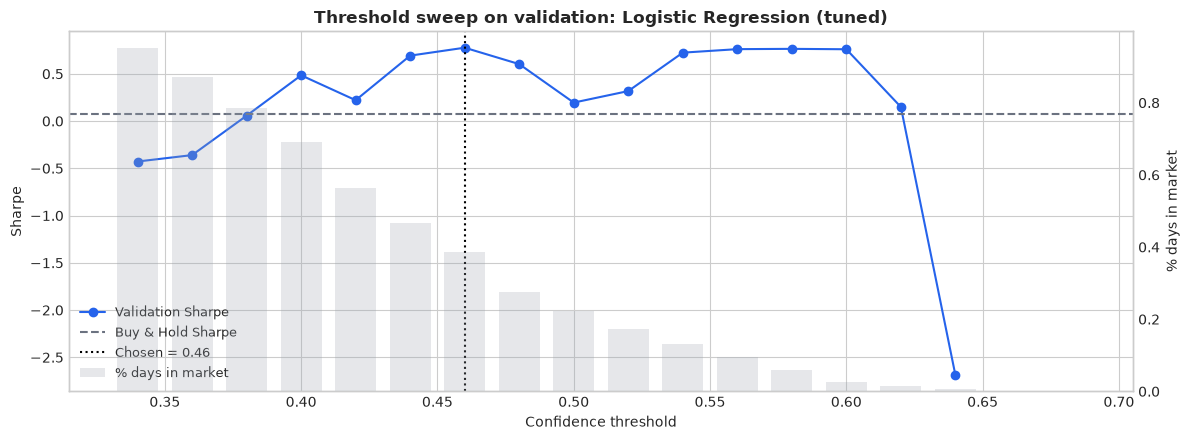

Chosen confidence threshold: 0.46


,Threshold,Sharpe,CAGR,Macro F1,Trades,% Days in Market
0,0.340000,-0.43,-33.2%,25.0%,54,95%
1,0.360000,-0.36,-29.5%,26.2%,64,87%
2,0.380000,0.06,-9.6%,27.3%,59,78%
3,0.400000,0.48,14.8%,28.2%,73,69%
4,0.420000,0.22,1.1%,27.0%,65,56%
5,0.440000,0.69,25.8%,26.3%,59,47%
6,0.460000,0.78,28.9%,24.7%,63,39%
7,0.480000,0.60,19.1%,22.3%,49,28%
8,0.500000,0.20,3.0%,21.5%,39,22%
9,0.520000,0.32,7.4%,20.5%,43,17%


In [51]:
val_proba = best_model_trainfit.predict_proba(X_val)
sweep = []
for th in np.round(np.arange(0.34, 0.70, 0.02), 2):
    sig = signals_from_proba(val_proba, best_model_trainfit.classes_, th)
    bt = run_backtest(df_model.loc[val_idx, "Close"], sig)
    fm = financial_metrics(bt["Strategy_Return"])
    sweep.append({"Threshold": th, "Sharpe": fm["Sharpe"], "CAGR": fm["CAGR"],
                  "Macro F1": f1_score(y_val, sig, average="macro", labels=[-1, 0, 1], zero_division=0),
                  "Trades": int((bt["Turnover"] > 0).sum()), "% Days in Market": (bt["Position"] != 0).mean()})
sweep = pd.DataFrame(sweep)
eligible = sweep[(sweep["Trades"] >= MIN_TRADES) & sweep["Sharpe"].notna()]
BEST_THRESHOLD = float(eligible.loc[eligible["Sharpe"].idxmax(), "Threshold"]) if len(eligible) else DEFAULT_CONFIDENCE

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(sweep["Threshold"], sweep["Sharpe"], "o-", color=COLORS["strategy"], label="Validation Sharpe")
ax1.axhline(buyhold_row(val_idx)["Sharpe"], color=COLORS["buyhold"], ls="--", label="Buy & Hold Sharpe")
ax1.axvline(BEST_THRESHOLD, color="black", ls=":", label=f"Chosen = {BEST_THRESHOLD:.2f}")
ax1.set_xlabel("Confidence threshold"); ax1.set_ylabel("Sharpe")
ax2 = ax1.twinx()
ax2.bar(sweep["Threshold"], sweep["% Days in Market"], width=0.015, alpha=0.25, color=COLORS[0], label="% days in market")
ax2.set_ylabel("% days in market"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="best", fontsize=9)
ax1.set_title(f"Threshold sweep on validation: {best_label}")
plt.tight_layout(); save_fig("tuning_threshold_sweep"); plt.show()
print(f"Chosen confidence threshold: {BEST_THRESHOLD:.2f}")
sweep.style.format({"Sharpe": "{:.2f}", "CAGR": "{:.1%}", "Macro F1": "{:.1%}", "% Days in Market": "{:.0%}"}, na_rep="–")

## 8. Final Evaluation on the Sealed Test Set (2023–2024)

The chosen model and threshold are **refitted once on train + validation** (2012–2022, purged before 2023) and scored **once** on the test set. Nothing below is used to change the model.

**Metrics and why they fit the business problem**

| Metric | Why |
|---|---|
| **Sharpe ratio** (primary) | The desk cares about return per unit of risk, after costs, not raw accuracy. |
| **Max drawdown** | Clients feel losses from peaks; drawdown is a key risk limit. |
| **Buy / Sell precision** | When the model says "trade", how often is it right? False signals cost fees and money. |
| **Macro F1, balanced accuracy** | Classification quality with every class counted equally (accuracy alone can be fooled, as with the Dummy). |
| **ROC AUC (one-vs-rest)** | Threshold-free check of how well probabilities *rank* days. 0.5 means no skill. |

In [52]:
final_model = clone(best_model_trainfit).fit(df_model.loc[trval_idx, FEATURE_COLS], df_model.loc[trval_idx, "Target"])
test_row, test_sig, test_proba, test_bt = evaluate(final_model, X_test, y_test, test_idx, BEST_THRESHOLD, best_label)
val_row = evaluate(best_model_trainfit, X_val, y_val, val_idx, BEST_THRESHOLD, best_label)[0]

strat_fm = financial_metrics(test_bt["Strategy_Return"])
bh_fm = financial_metrics(test_bt["BuyHold_Return"])

print(f"Model: {best_label} | threshold {BEST_THRESHOLD:.2f} | data: {DATA_SOURCE}\n")
print(classification_report(y_test, test_sig, labels=[-1, 0, 1],
                            target_names=[CLASS_NAMES[c] for c in (-1, 0, 1)], zero_division=0))

compare = pd.DataFrame({
    "Validation (2021-22)": {k: val_row[k] for k in ("Macro F1", "Buy Precision", "Sell Precision", "ROC AUC (OvR)", "Sharpe", "CAGR", "Max Drawdown", "Trades")},
    "Test (2023-26)":       {k: test_row[k] for k in ("Macro F1", "Buy Precision", "Sell Precision", "ROC AUC (OvR)", "Sharpe", "CAGR", "Max Drawdown", "Trades")},
})
compare.to_csv(f"{OUTPUT_DIR}/validation_vs_test.csv")
compare

Model: Logistic Regression (tuned) | threshold 0.46 | data: Yahoo Finance (cached)

              precision    recall  f1-score   support

   Sell (-1)       0.35      0.04      0.07       280
    Hold (0)       0.37      0.84      0.51       321
     Buy (1)       0.48      0.24      0.32       318

    accuracy                           0.39       919
   macro avg       0.40      0.37      0.30       919
weighted avg       0.40      0.39      0.31       919



,Validation (2021-22),Test (2023-26)
Macro F1,0.246963,0.300593
Buy Precision,0.362069,0.477987
Sell Precision,0.428571,0.354839
ROC AUC (OvR),0.476596,0.585000
Sharpe,0.776413,0.988909
CAGR,0.288709,0.332233
Max Drawdown,-0.322485,-0.398669
Trades,63.000000,68.000000


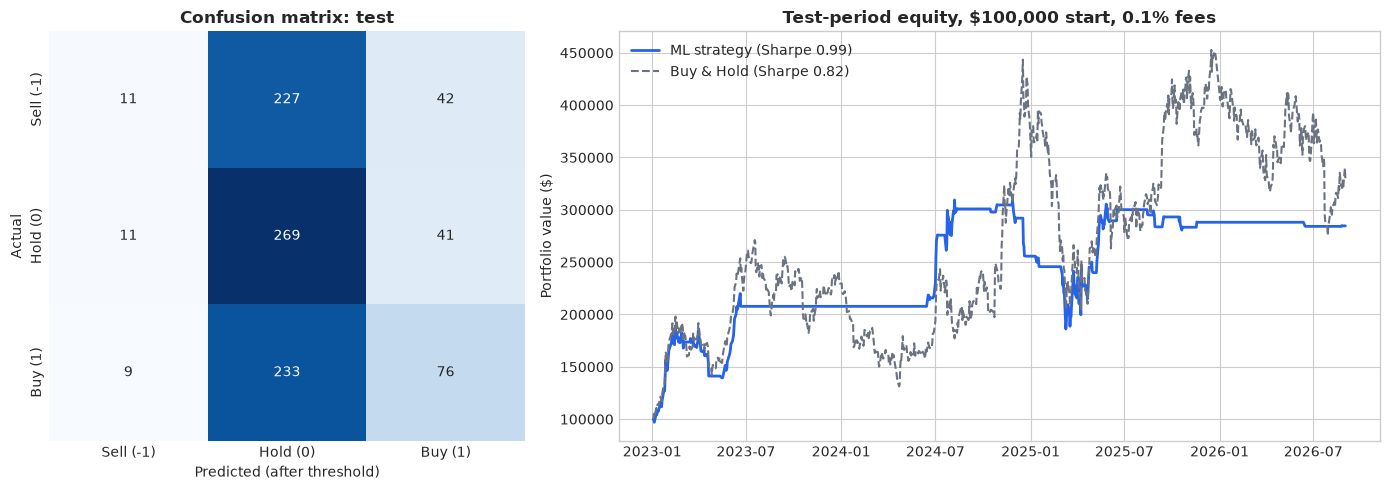

,ML Strategy,Buy & Hold
Total Return,184.7%,229.1%
CAGR,33.2%,38.6%
Volatility,32.1%,57.8%
Sharpe,0.99,0.82
Sortino,1.66,1.26
Max Drawdown,-39.9%,-53.8%
Trades,68,1
% Days in Market,20.7%,100.0%


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
cm = confusion_matrix(y_test, test_sig, labels=[-1, 0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=[CLASS_NAMES[c] for c in (-1, 0, 1)], yticklabels=[CLASS_NAMES[c] for c in (-1, 0, 1)])
axes[0].set_xlabel("Predicted (after threshold)"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix: test")

axes[1].plot(test_bt.index, test_bt["Strategy_Equity"], color=COLORS["strategy"], lw=2,
             label=f"ML strategy (Sharpe {strat_fm['Sharpe']:.2f})")
axes[1].plot(test_bt.index, test_bt["BuyHold_Equity"], color=COLORS["buyhold"], ls="--",
             label=f"Buy & Hold (Sharpe {bh_fm['Sharpe']:.2f})")
axes[1].set_title(f"Test-period equity, ${INITIAL_CAPITAL:,.0f} start, {TRANSACTION_FEE:.1%} fees")
axes[1].set_ylabel("Portfolio value ($)"); axes[1].legend()
plt.tight_layout(); save_fig("test_confusion_and_equity"); plt.show()

fin_table = pd.DataFrame({"ML Strategy": strat_fm, "Buy & Hold": bh_fm})
fin_table.loc["Trades"] = [test_row["Trades"], 1]
fin_table.loc["% Days in Market"] = [test_row["% Days in Market"], 1.0]
fin_table.to_csv(f"{OUTPUT_DIR}/test_financial_metrics.csv")
styler = fin_table.style
for r in fin_table.index:
    styler = styler.format({"Sharpe": "{:.2f}", "Sortino": "{:.2f}", "Trades": "{:.0f}"}.get(r, "{:.1%}"),
                           subset=pd.IndexSlice[[r], :])
styler

### 8.1 Error analysis: where does the model fail?

1. **By volatility regime** (cut-offs set on *training* data): does the model only work in calm markets?
2. **By quarter**: is performance stable, or driven by one lucky period?
3. **Signal quality**: what actually happened after Buy and Sell signals, and how often did the model call the exact opposite direction?

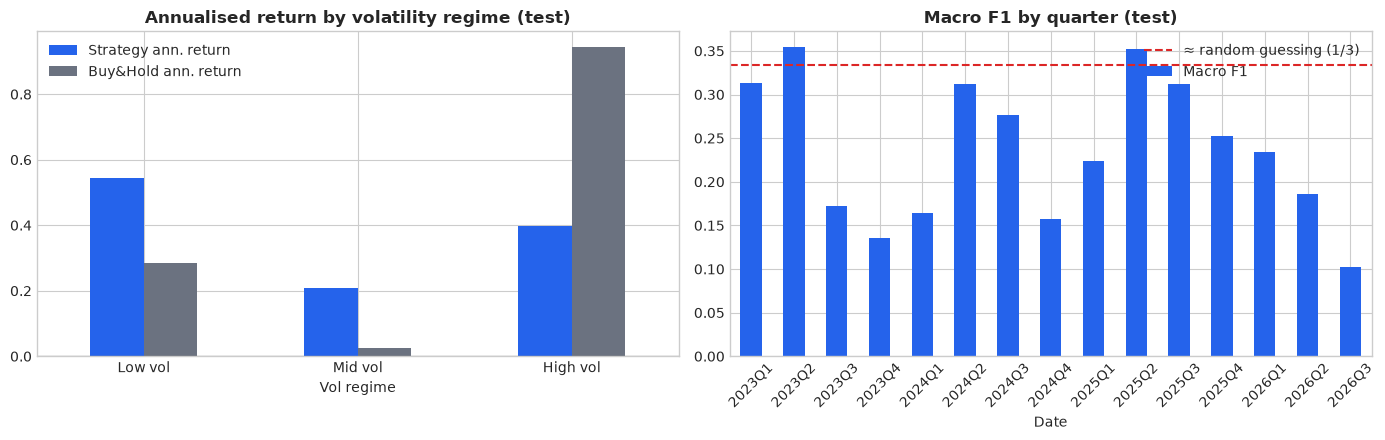

Signal quality (test):


,Signals issued,Avg future 5d return,% future return > 0,Opposite-direction errors
Buy (1),159.0,0.123733,0.628931,42.0
Hold (0),729.0,0.017407,0.510288,NaN
Sell (-1),31.0,0.048024,0.483871,9.0


,Days,Macro F1,Strategy ann. return,Buy&Hold ann. return
Vol regime,,,,
Low vol,110,35.5%,54.3%,28.6%
Mid vol,374,27.7%,20.8%,2.7%
High vol,435,29.8%,39.6%,94.5%


In [54]:
ea = df_model.loc[test_idx, ["Close", "Future_Return", "Target", "Vol_20D"]].copy()
ea["Signal"] = test_sig
ea["Strategy_Return"] = test_bt["Strategy_Return"]
ea["BuyHold_Return"] = test_bt["BuyHold_Return"]

lo, hi = df_model.loc[train_idx, "Vol_20D"].quantile([1 / 3, 2 / 3])
ea["Vol regime"] = pd.cut(ea["Vol_20D"], [-np.inf, lo, hi, np.inf], labels=["Low vol", "Mid vol", "High vol"])

def segment_stats(g):
    return pd.Series({
        "Days": len(g),
        "Macro F1": f1_score(g["Target"], g["Signal"], average="macro", labels=[-1, 0, 1], zero_division=0),
        "Strategy ann. return": g["Strategy_Return"].mean() * 252,
        "Buy&Hold ann. return": g["BuyHold_Return"].mean() * 252,
    })

by_regime = ea.groupby("Vol regime", observed=False).apply(segment_stats)
by_quarter = ea.groupby(ea.index.to_period("Q")).apply(segment_stats)
by_regime.to_csv(f"{OUTPUT_DIR}/error_by_regime.csv"); by_quarter.to_csv(f"{OUTPUT_DIR}/error_by_quarter.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_regime[["Strategy ann. return", "Buy&Hold ann. return"]].plot(kind="bar", ax=axes[0], color=[COLORS["strategy"], COLORS["buyhold"]], rot=0)
axes[0].set_title("Annualised return by volatility regime (test)"); axes[0].axhline(0, color="black", lw=0.8)
by_quarter["Macro F1"].plot(kind="bar", ax=axes[1], color=COLORS["strategy"], rot=45)
axes[1].axhline(1 / 3, color=COLORS[-1], ls="--", label="≈ random guessing (1/3)")
axes[1].set_title("Macro F1 by quarter (test)"); axes[1].legend()
plt.tight_layout(); save_fig("error_analysis_segments"); plt.show()

signal_quality = pd.DataFrame({
    CLASS_NAMES[s]: {
        "Signals issued": int((ea["Signal"] == s).sum()),
        "Avg future 5d return": ea.loc[ea["Signal"] == s, "Future_Return"].mean(),
        "% future return > 0": (ea.loc[ea["Signal"] == s, "Future_Return"] > 0).mean(),
        "Opposite-direction errors": int(((ea["Signal"] == s) & (ea["Target"] == -s)).sum()) if s != 0 else np.nan,
    } for s in (1, 0, -1)}).T
print("Signal quality (test):")
display(signal_quality)
display(by_regime.style.format({"Macro F1": "{:.1%}", "Strategy ann. return": "{:.1%}", "Buy&Hold ann. return": "{:.1%}", "Days": "{:.0f}"}))

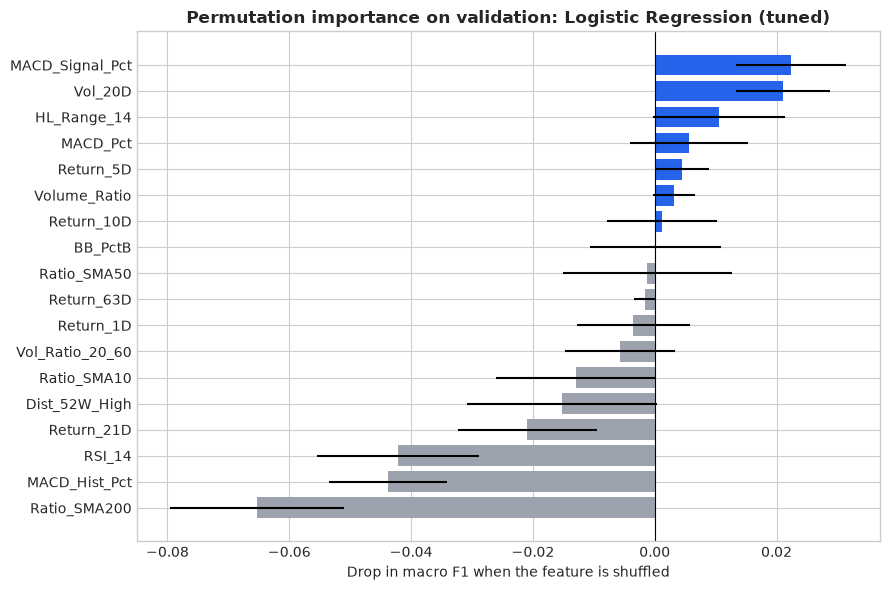

Top 5 features: MACD_Signal_Pct, Vol_20D, HL_Range_14, MACD_Pct, Return_5D


In [55]:
# What drives the predictions? Permutation importance on VALIDATION (model fitted on train only)
pi = permutation_importance(best_model_trainfit, X_val, y_val, scoring="f1_macro", n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURE_COLS).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=FEATURE_COLS)[imp.index],
        color=[COLORS["strategy"] if v > 0 else COLORS[0] for v in imp.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Permutation importance on validation: {best_label}")
ax.set_xlabel("Drop in macro F1 when the feature is shuffled")
plt.tight_layout(); save_fig("feature_importance"); plt.show()
print("Top 5 features:", ", ".join(imp.sort_values(ascending=False).index[:5]))

**How to talk about errors in the presentation:** name the regime or quarter where the model loses most, show the opposite-direction error count (the costliest mistakes: calling Buy before a fall), and note that importance shows **association, not causation**.

## 9. Opportunity Sizing

The value of the model is the **extra return over the current process (buy-and-hold)**, scaled to the capital the desk would actually allocate, minus the cost of building and running it. Every assumption is a parameter below; change them to match your story.

In [56]:
# ---- Assumptions (edit these) ----
AUM               = 1_000_000   # capital the desk would run with the model ($)
BUILD_HOURS, HOURLY_RATE = 120, 80          # one-off build effort
ANNUAL_DATA_COST  = 1_200       # market-data licence ($/yr)
ANNUAL_INFRA_COST = 600         # cloud compute + storage ($/yr)
ANNUAL_MAINT_HOURS = 40         # monitoring, retraining, reviews (hours/yr)
N_BOOT, BLOCK = 2000, 20        # block bootstrap settings for the confidence interval

build_cost = BUILD_HOURS * HOURLY_RATE
annual_run_cost = ANNUAL_DATA_COST + ANNUAL_INFRA_COST + ANNUAL_MAINT_HOURS * HOURLY_RATE

excess_cagr = strat_fm["CAGR"] - bh_fm["CAGR"]
annual_value = excess_cagr * AUM
year1_net = annual_value - build_cost - annual_run_cost
breakeven_aum = (annual_run_cost + build_cost) / excess_cagr if excess_cagr > 0 else np.nan
drawdown_saving = (strat_fm["Max Drawdown"] - bh_fm["Max Drawdown"]) * AUM   # positive = smaller worst loss

# Block bootstrap of daily excess returns (keeps volatility clusters together)
rng = np.random.default_rng(RANDOM_STATE)
diff = (test_bt["Strategy_Return"] - test_bt["BuyHold_Return"]).values
n = len(diff)
boot = np.empty(N_BOOT)
for b in range(N_BOOT):
    starts = rng.integers(0, n - BLOCK, size=int(np.ceil(n / BLOCK)))
    sample = np.concatenate([diff[s:s + BLOCK] for s in starts])[:n]
    boot[b] = sample.mean() * 252
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
p_positive = (boot > 0).mean()

sizing = pd.DataFrame.from_dict({
    "Test-period excess CAGR vs Buy & Hold": f"{excess_cagr:+.2%}",
    "95% CI of annual excess return (bootstrap)": f"[{ci_low:+.2%}, {ci_high:+.2%}]",
    "Probability excess return > 0": f"{p_positive:.0%}",
    f"Annual value on ${AUM:,.0f} AUM": f"${annual_value:,.0f}",
    "Change in worst drawdown on AUM": f"${drawdown_saving:,.0f}",
    "One-off build cost": f"${build_cost:,.0f}",
    "Annual running cost": f"${annual_run_cost:,.0f}",
    "Year-1 net value": f"${year1_net:,.0f}",
    "Break-even AUM (year 1)": f"${breakeven_aum:,.0f}" if np.isfinite(breakeven_aum) else "n/a (no excess return)",
}, orient="index", columns=["Value"])
sizing.to_csv(f"{OUTPUT_DIR}/opportunity_sizing.csv")
sizing

,Value
Test-period excess CAGR vs Buy & Hold,-5.40%
95% CI of annual excess return (bootstrap),"[-63.48%, +34.43%]"
Probability excess return > 0,31%
"Annual value on $1,000,000 AUM","$-54,042"
Change in worst drawdown on AUM,"$138,988"
One-off build cost,"$9,600"
Annual running cost,"$5,000"
Year-1 net value,"$-68,642"
Break-even AUM (year 1),n/a (no excess return)


**Reading the numbers:** a positive point estimate is not enough. If the 95% interval includes zero, two years of test data cannot distinguish skill from luck, which is common with a single stock over a short window.

## 10. Recommendation: Deploy or Not Deploy

In [57]:
checks = {
    "Uses real market data (not synthetic)": not IS_SYNTHETIC,
    "Test Sharpe beats Buy & Hold": bool(np.nan_to_num(strat_fm["Sharpe"], nan=-9) > bh_fm["Sharpe"]),
    "Beats the no-skill Dummy on macro F1 (validation)": bool(val_row["Macro F1"] >
        evaluate(fitted_default["Majority class (Dummy)"], X_val, y_val, val_idx, BEST_THRESHOLD)[0]["Macro F1"]),
    "Excess return statistically above zero (CI lower bound > 0)": bool(ci_low > 0),
    "Year-1 value exceeds build + running cost": bool(year1_net > 0),
}
for k, v in checks.items():
    print(f"  [{'PASS' if v else 'FAIL'}] {k}")

if all(checks.values()):
    RECOMMENDATION = "DEPLOY to paper trading (shadow mode), then a small-capital A/B test"
elif checks["Uses real market data (not synthetic)"] and checks["Test Sharpe beats Buy & Hold"]:
    RECOMMENDATION = "DO NOT DEPLOY YET: promising, but the edge is not yet statistically reliable or cost-justified; run paper trading"
else:
    RECOMMENDATION = "DO NOT DEPLOY: the model does not beat the current buy-and-hold process after costs"
print(f"\nRECOMMENDATION -> {RECOMMENDATION}")

  [PASS] Uses real market data (not synthetic)
  [PASS] Test Sharpe beats Buy & Hold
  [PASS] Beats the no-skill Dummy on macro F1 (validation)
  [FAIL] Excess return statistically above zero (CI lower bound > 0)
  [FAIL] Year-1 value exceeds build + running cost

RECOMMENDATION -> DO NOT DEPLOY YET: promising, but the edge is not yet statistically reliable or cost-justified; run paper trading


**Risks and limitations to state alongside the recommendation**

| Risk | Why it matters | Mitigation |
|---|---|---|
| **Overfitting to history** | Many settings were tried; some apparent skill may be luck. | Sealed test set, purged CV, confidence interval, paper trading before real money. |
| **Regime change / drift** | Market behaviour changes (rates, AI cycle, regulation). | Drift monitoring and scheduled retraining (§11). |
| **Short selling risk** | Shorts have unlimited loss and borrowing costs not modelled here. | Set `LONG_ONLY = True` for a more conservative version. |
| **Costs underestimated** | Slippage can exceed 0.1% in volatile markets. | Re-run the backtest at 0.2–0.3% fees as a stress test. |
| **Single-stock concentration** | Results depend on one company. | Extend to a basket of tickers before scaling capital. |
| **Regulatory / suitability** | Automated signals given to clients may count as investment advice (e.g. MAS rules in Singapore). | Human sign-off on trades; compliance review before client use. |

*"Do not deploy yet" is a valid and often the most credible answer for a trading model, as long as the evidence above supports it.*

In [58]:
# Monitoring demo: PSI of each feature in the test period vs. training data
def psi(expected, actual, bins=10):
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    e = np.histogram(expected, cuts)[0] / len(expected)
    a = np.histogram(actual, cuts)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

drift = pd.Series({f: psi(X_train[f].values, X_test[f].values) for f in FEATURE_COLS}).sort_values(ascending=False)
drift_df = pd.DataFrame({"PSI": drift, "Status": pd.cut(drift, [-np.inf, 0.1, 0.25, np.inf],
                                                        labels=["Stable", "Watch", "Drift - investigate"])})
drift_df.to_csv(f"{OUTPUT_DIR}/feature_drift_psi.csv")
drift_df.style.format({"PSI": "{:.3f}"})

,PSI,Status
HL_Range_14,1.661,Drift - investigate
Vol_20D,0.586,Drift - investigate
Ratio_SMA200,0.530,Drift - investigate
Dist_52W_High,0.509,Drift - investigate
Volume_Ratio,0.465,Drift - investigate
Return_63D,0.214,Watch
MACD_Signal_Pct,0.177,Watch
MACD_Pct,0.166,Watch
Ratio_SMA50,0.100,Stable
MACD_Hist_Pct,0.096,Stable


## Lessons Learned

1. **Accuracy is a lie here too.** A majority-class model can look accurate; macro F1, precision on trade signals, and above all **after-cost Sharpe vs buy-and-hold** are the honest measures.
2. **Time-series discipline matters more than model choice:** no shuffling, purge gaps, `TimeSeriesSplit` with `gap`, execution one day after the signal, and a test set opened only once.
3. **Simple, regularised models are competitive on noisy data.** Tuning showed complexity controls (depth, leaf size, regularisation) matter most: a bias–variance story.
4. **The confidence threshold is a business lever.** A higher threshold means fewer, more selective trades and lower fee drag, at the cost of time out of the market.
5. **Single-stock prediction has a small edge at best**, so statistical uncertainty (bootstrap CI) must be part of the go/no-go decision.

In [59]:
README_TEMPLATE = r'''# TSLA ML Trading Model: Predicting 5-Day Price Direction

Module 3 Project (SCTP Advanced Professional Certificate in Data Science & AI)

## Project overview and problem statement

An investment desk holds Tesla (TSLA) and must decide each day whether to be **long, flat or short** for the coming week. Today it simply **buys and holds**. This project builds a machine-learning model that predicts whether TSLA's next 20-day return will be:

| Label | Rule |
|---|---|
| Buy (+1) | 20-day return > +6.0% |
| Hold (0) | between −6.0% and +6.0% |
| Sell (−1) | 20-day return < −6.0% |

The model's probabilities, filtered by a confidence threshold, become daily trading signals. They are judged against buy-and-hold on **after-cost risk-adjusted return (Sharpe ratio)** and drawdown, followed by a deploy / don't-deploy recommendation.

**ML problem type:** supervised, multi-class classification on time-series data, with daily batch predictions.

## Dataset

- **Source:** Yahoo Finance daily OHLCV for `TSLA`, split- and dividend-adjusted, via the [`yfinance`](https://pypi.org/project/yfinance/) library
- **Period:** 2012-01-01 to 2026-10-01 
- **Features:** 18 scale-free technical features (returns, moving-average ratios, RSI, price-normalised MACD, Bollinger %B, volatility and volume ratios)
- **Splits (chronological, purged):** train 2012–2020 · validation 2021–2022 · test 2023–2026

**How to obtain it:** the notebook downloads the data automatically on first run and caches it to `data/tsla_ohlcv.csv`. Yahoo data is for personal and educational use, so the CSV is not committed to this repository.

> If the download fails (no internet), the notebook falls back to **synthetic** data and prints a warning. Synthetic results have no real-world meaning.

## Method summary

1. **Baselines:** buy-and-hold (the current process) and a majority-class `DummyClassifier`
2. **Models:** Logistic Regression (scaled, L2), Random Forest, Histogram Gradient Boosting, all with balanced class weights
3. **Tuning:** `GridSearchCV` with `TimeSeriesSplit(n_splits=5, gap=5)` on training data, scored by macro F1
4. **Model and threshold selection** on the 2021–2022 validation set
5. **Single final test** on 2023–2026 after refitting on 2012–2022
6. **Backtest:** signal after the close on day *t*, filled at the close of *t*+1, 0.1% cost per unit of position change
7. **Error analysis** by volatility regime and quarter; permutation feature importance
8. **Opportunity sizing** with a block-bootstrap confidence interval on excess return

**Leakage controls:** backward-looking features only (verified by an automated check), purge gaps between splits, time-series cross-validation with a gap, and a scaler fitted inside a `Pipeline`.

## Repository structure

```
.
├── tsla_trading_model_v2.ipynb      # full analysis (sections 1–12 follow the assignment brief)
├── requirements.txt
├── README.md
├── data/                         # cached Yahoo download (created on first run, git-ignored)
└── outputs/                      # created by the notebook
    ├── figures/                  # PNG charts for slides
    ├── model_comparison_*.csv    # baseline / tuned model tables (validation)
    ├── validation_vs_test.csv
    ├── test_financial_metrics.csv
    ├── error_by_regime.csv, error_by_quarter.csv
    ├── opportunity_sizing.csv
    ├── feature_drift_psi.csv
    ├── test_signals.csv
    ├── final_model.joblib        # model + threshold + feature list
    └── results_summary.md
```

## Deployment architecture (proposed)

```mermaid
flowchart LR
    A[Market data<br/>daily after close] --> B[Ingestion job<br/>+ data checks]
    B --> C[Feature pipeline]
    C --> D[Batch prediction<br/>model + threshold]
    R[(Model registry)] --> D
    D --> E[Signal store / API]
    E --> F[PM review → broker<br/>paper or live]
    E --> G[Monitoring<br/>PSI drift, rolling Sharpe,<br/>drawdown kill switch]
    G -->|monthly retrain| R
```

## Disclaimer

Educational project only. This is not investment advice.
'''

readme = README_TEMPLATE.replace('{{RESULTS}}', summary.split('\n', 1)[1].strip())
with open('README.md', 'w') as f:
    f.write(readme)
print(f'README.md written ({len(readme):,} characters). Files ready for GitHub:')
for p in ['tsla_trading_model_v2.ipynb', 'README.md', 'requirements.txt', 'outputs/']:
    print('  ', p, '✓' if os.path.exists(p) else '(missing)')
if IS_SYNTHETIC:
    print('\nWARNING: results come from SYNTHETIC data. Re-run with internet access before publishing.')

README.md written (4,020 characters). Files ready for GitHub:
   tsla_trading_model_v2.ipynb ✓
   README.md ✓
   requirements.txt ✓
   outputs/ ✓


## 12. Save Artifacts for the GitHub Repository

Saves the trained model, test signals and a `results_summary.md` you can paste into the README's *Results* section.

In [60]:
joblib.dump({"model": final_model, "threshold": BEST_THRESHOLD, "features": FEATURE_COLS,
             "horizon": FUTURE_PERIOD, "buy_threshold": BUY_THRESHOLD, "sell_threshold": SELL_THRESHOLD},
            f"{OUTPUT_DIR}/final_model.joblib")
ea[["Close", "Signal", "Target", "Future_Return", "Strategy_Return"]].to_csv(f"{OUTPUT_DIR}/test_signals.csv")

summary = f'''# Results summary ({TICKER})

- **Data:** {DATA_SOURCE}, {df_model.index.min():%Y-%m-%d} to {df_model.index.max():%Y-%m-%d}, {len(df_model):,} modelling rows, {len(FEATURE_COLS)} features
- **Target:** {FUTURE_PERIOD}-day return > {BUY_THRESHOLD:+.1%} = Buy, < {SELL_THRESHOLD:+.1%} = Sell, else Hold
- **Selected model:** {best_label}, params {searches[best_name].best_params_}, confidence threshold {BEST_THRESHOLD:.2f}

| Test 2023-24 | ML strategy | Buy & Hold |
|---|---|---|
| CAGR | {strat_fm['CAGR']:.1%} | {bh_fm['CAGR']:.1%} |
| Sharpe | {strat_fm['Sharpe']:.2f} | {bh_fm['Sharpe']:.2f} |
| Max drawdown | {strat_fm['Max Drawdown']:.1%} | {bh_fm['Max Drawdown']:.1%} |
| Macro F1 | {test_row['Macro F1']:.1%} | – |
| Trades | {test_row['Trades']} | 1 |

- **Excess return 95% CI:** [{ci_low:+.2%}, {ci_high:+.2%}] per year
- **Recommendation:** {RECOMMENDATION}
'''
with open(f"{OUTPUT_DIR}/results_summary.md", "w") as f:
    f.write(summary)
print(summary)
print("Saved files:", sorted(os.listdir(OUTPUT_DIR)))

# Results summary (TSLA)

- **Data:** Yahoo Finance (cached), 2013-01-03 to 2026-09-01, 3,436 modelling rows, 18 features
- **Target:** 20-day return > +6.0% = Buy, < -6.0% = Sell, else Hold
- **Selected model:** Logistic Regression (tuned), params {'clf__C': 0.1}, confidence threshold 0.46

| Test 2023-24 | ML strategy | Buy & Hold |
|---|---|---|
| CAGR | 33.2% | 38.6% |
| Sharpe | 0.99 | 0.82 |
| Max drawdown | -39.9% | -53.8% |
| Macro F1 | 30.1% | – |
| Trades | 68 | 1 |

- **Excess return 95% CI:** [-63.48%, +34.43%] per year
- **Recommendation:** DO NOT DEPLOY YET: promising, but the edge is not yet statistically reliable or cost-justified; run paper trading

Saved files: ['error_by_quarter.csv', 'error_by_regime.csv', 'feature_drift_psi.csv', 'figures', 'final_model.joblib', 'model_comparison_default.csv', 'model_comparison_tuned.csv', 'opportunity_sizing.csv', 'results_summary.md', 'test_financial_metrics.csv', 'test_signals.csv', 'validation_vs_test.csv']
